<a href="https://colab.research.google.com/github/Ghazal-Rouhani/DSC_110/blob/main/ML_Evaluation_Explainability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Model Evaluation and Explanation**

Model Evaluation

Evaluation of Classification models

Pandas helps us load and work with datasets. Matplotlib is used to visualize the data and model evaluation results. This imports the Random Forest classification model. Random Forest combines multiple decision trees to make more reliable predictions. These functions help us evaluate the model by comparing actual and predicted classes.
ConfusionMatrixDisplay allows us to visualize correct and incorrect predictions.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

These lines load the training and testing datasets directly from GitHub.
X contains the input features, while y contains the actual classification labels.
The training data is used to train the model, and the testing data is used to evaluate its performance on data it has not seen before. We convert the target variables from DataFrames into one-dimensional Series because the classification model expects the labels in this format. This also helps prevent unnecessary warnings.

In [ ]:
X_train = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/X_train.csv')
X_test = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/X_test.csv')
y_train = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/y_train.csv')
y_test = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/y_test.csv')

#to prevent warning, converting the y from df to 1d series
y_train = y_train.squeeze()
y_test  = y_test.squeeze()

This creates a Random Forest classification model. Setting random_state to 42 helps us get reproducible results when running the same code multiple times.
This trains the model using the training features and their actual labels. During training, the model learns patterns in the data that can help distinguish between patients with and without diabetes.

In [ ]:
#Build the model
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

Importing evaluation metrics to measure the performance of the classification model. The classification report includes precision, recall, F1-score, and support. The ROC-AUC score measures how well the model distinguishes between the two classes.
Using the trained model to predict the class of each observation in the testing dataset.
Calculating the probability of each observation belonging to the positive class (diabetes).
The index [:, 1] selects the probabilities associated with the positive class.
Comparing the actual labels with the predicted labels and displaying different evaluation metrics to understand the model's performance.
Displaying the classification report specifically for the positive class (optional):
print(classification_report(y_test, y_pred, labels=[1]))
Calculating the area under the ROC curve using the predicted probabilities. An AUC closer to 1 indicates a better ability to distinguish between the two classes, while an AUC of 0.5 indicates performance similar to random guessing. The result is displayed with four decimal places.

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score

y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
#print(classification_report(y_test, y_pred, labels=[1]))
print(f"AUC-ROC: {roc_auc_score(y_test, y_prob):.4f}")

              precision    recall  f1-score   support

           0       0.86      0.97      0.91      1289
           1       0.29      0.06      0.11       216

    accuracy                           0.84      1505
   macro avg       0.58      0.52      0.51      1505
weighted avg       0.78      0.84      0.80      1505

AUC-ROC: 0.7488


==============================

ALL THE BELOW IS DEMO

You don't need to comment on it

Changing the threshold

In [ ]:
# Changing threshold to 0.3: classify as positive if prob >= 0.3
y_pred_03 = (y_prob >= 0.3).astype(int)

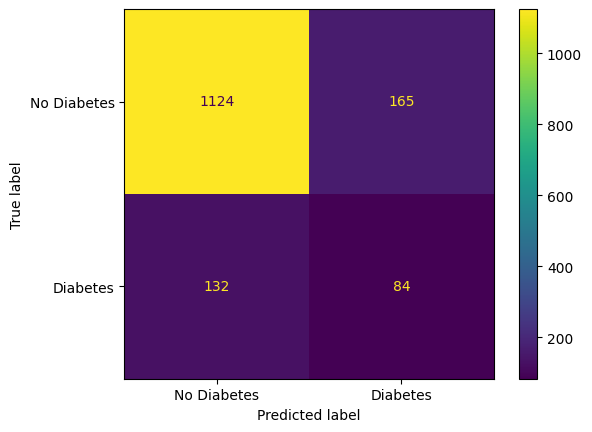

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_03, display_labels=['No Diabetes', 'Diabetes'])
plt.show()

In [ ]:
# Changing threshold to 0.7: classify as positive if prob >= 0.7
y_pred_07 = (y_prob >= 0.7).astype(int)

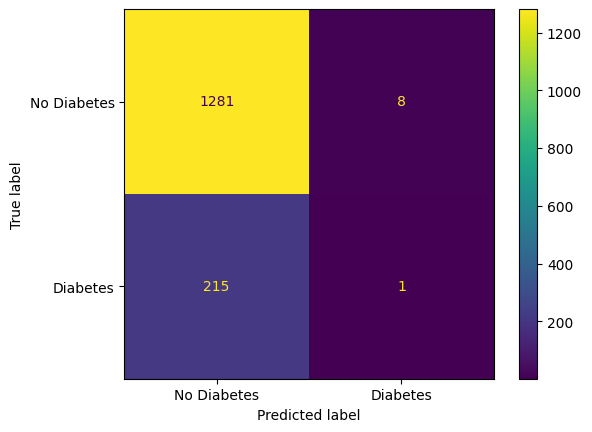

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_07, display_labels=['No Diabetes', 'Diabetes'])
plt.show()

Explainability

SHAP

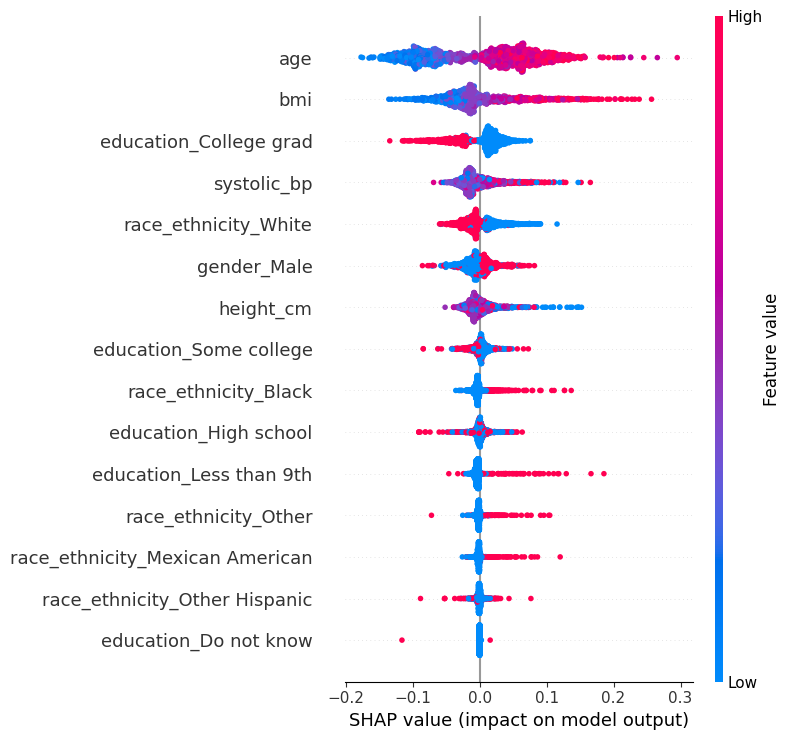

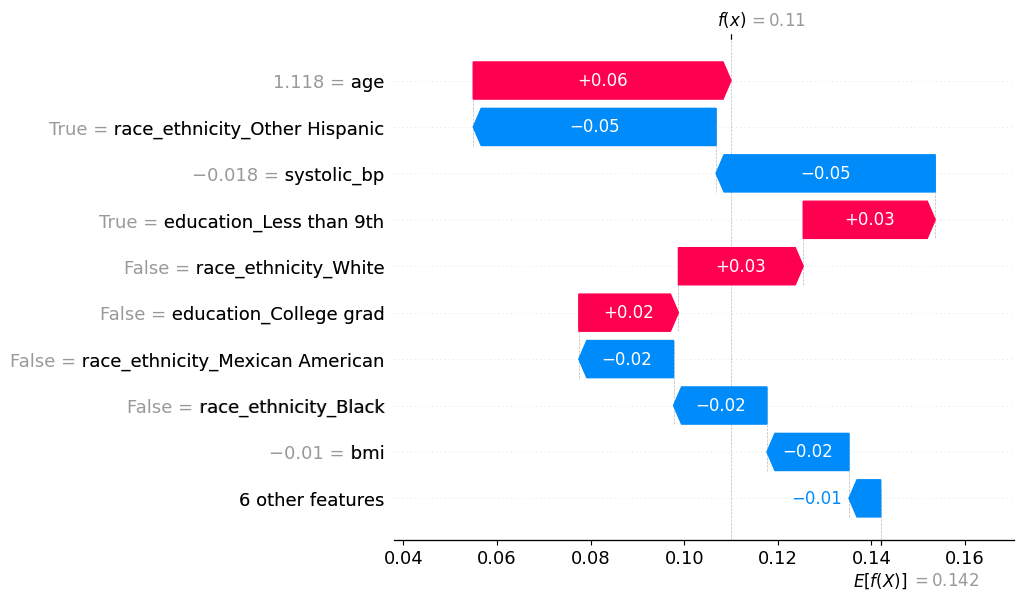

In [ ]:
import shap

explainer = shap.TreeExplainer(rf)
shap_values = explainer(X_test)          # newer API — returns Explanation object

# overall summary plot
shap.summary_plot(shap_values[:, :, 1], X_test)   # [:, :, 1] = all rows, all features, positive class

# single observation (row 0)
shap.plots.waterfall(shap_values[0, :, 1])         # cleaner than force_plot for single obs

Partial Dependence Plot (PDP)

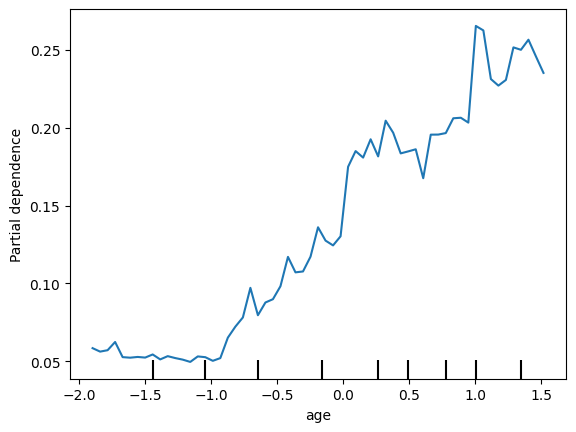

In [ ]:
from sklearn.inspection import PartialDependenceDisplay

# replace 'age' with any feature name (or column index)
PartialDependenceDisplay.from_estimator(
    rf,
    X_test,
    features=['age']          # list of features to plot
)

Feature Importance Plot

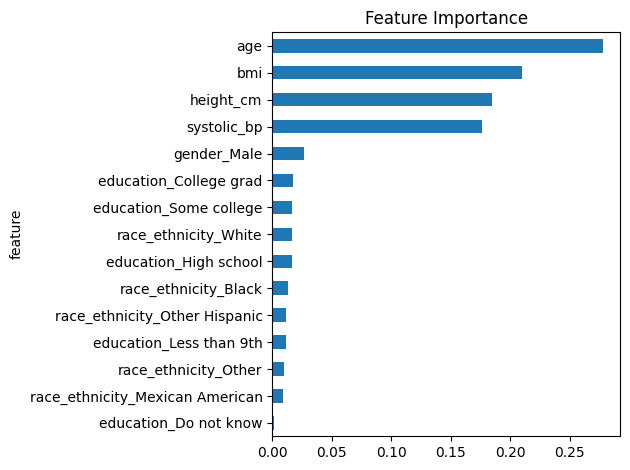

In [ ]:
importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=True)

importance_df.plot(
    kind='barh',
    x='feature', y='importance',
    legend=False, title='Feature Importance'
)
plt.tight_layout()
plt.show()

Auto ML

In [ ]:
pip install h2o

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 266.4/266.4 MB 4.4 MB/s eta 0:00:00


In [ ]:
import h2o
from h2o.automl import H2OAutoML

h2o.init()

# convert your existing splits
train = h2o.H2OFrame(X_train.assign(target=y_train))
test  = h2o.H2OFrame(X_test.assign(target=y_test))

x = X_train.columns.tolist()
y = 'target'

train['target'] = train['target'].asfactor()
test['target']  = test['target'].asfactor()

aml = H2OAutoML(max_models=10, seed=42)
aml.train(x=x, y=y, training_frame=train)

# leaderboard
aml.leaderboard.head()

# best model predictions
preds = aml.leader.predict(test)

Checking whether there is an H2O instance running at http://localhost:54321. connected.


H2O_cluster_uptime:,1 min 17 secs
H2O_cluster_timezone:,Etc/UTC
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.10
H2O_cluster_version_age:,12 days
H2O_cluster_name:,H2O_from_python_unknownUser_36t5ei
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.146 Gb
H2O_cluster_total_cores:,2
H2O_cluster_allowed_cores:,2
H2O_cluster_status:,"locked, healthy"


Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%
stackedensemble prediction progress: |███████████████████████████████████████████| (done) 100%


In [ ]:
aml.leaderboard.head()

model_id,auc,logloss,aucpr,mean_per_class_error,rmse,mse
StackedEnsemble_BestOfFamily_1_AutoML_2_20260324_171348,0.767293,0.350734,0.311718,0.315215,0.329683,0.108691
StackedEnsemble_AllModels_1_AutoML_2_20260324_171348,0.766339,0.351153,0.310419,0.32028,0.329881,0.108822
GBM_1_AutoML_2_20260324_171348,0.762645,0.35268,0.30575,0.311256,0.330413,0.109173
GLM_1_AutoML_2_20260324_171348,0.759653,0.354654,0.307912,0.310711,0.331129,0.109647
XGBoost_3_AutoML_2_20260324_171348,0.750242,0.364387,0.291629,0.319479,0.336064,0.112939
GBM_2_AutoML_2_20260324_171348,0.746515,0.361157,0.283594,0.326361,0.334452,0.111858
XGBoost_1_AutoML_2_20260324_171348,0.746264,0.368353,0.285342,0.325235,0.337847,0.114141
GBM_3_AutoML_2_20260324_171348,0.74545,0.362089,0.296462,0.321436,0.334017,0.111567
XRT_1_AutoML_2_20260324_171348,0.738048,0.372291,0.280878,0.310197,0.336078,0.112948
GBM_4_AutoML_2_20260324_171348,0.732616,0.368902,0.27834,0.330702,0.336916,0.113512
